In [1]:
import numpy as np
import polars as pl
import typol as tp
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

from Answer import Answer, AnswerWithoutQ11, AnswerQ11NullsAsOnes

In [2]:
# TODO Predict a person's reading habits (how much/often they read) according to their answers
def predict_habits(data: tp.DataFrame[AnswerQ11NullsAsOnes]):
    # we're trying to predict the enum HowManyBooksReadInTheLastSixMonths aka Question 11
    training_data: tp.DataFrame[AnswerWithoutQ11] = data.transform(AnswerWithoutQ11)
    X_train, X_test, y_train, y_test = train_test_split(
        training_data.dataframe, data[Answer.Q11_1].to_list(), test_size=0.20, random_state=0
    )
    X_train: tp.DataFrame[AnswerWithoutQ11] = tp.DataFrame(AnswerWithoutQ11, X_train)
    X_test: tp.DataFrame[AnswerWithoutQ11] = tp.DataFrame(AnswerWithoutQ11, X_test)
    y_train: tp.DataFrame[Answer] = tp.DataFrame(Answer, y_train)
    y_test: tp.DataFrame[Answer] = tp.DataFrame(Answer, y_test)
    predictor: RandomForestRegressor = RandomForestRegressor()
    predictor.fit(X_train, y_train)
    results: np.ndarray = predictor.predict(X_test)
    print(results)


In [9]:
def visualize_readership(data: tp.DataFrame[AnswerQ11NullsAsOnes]):
    df = data.dataframe.clone()
    counts = (
        df["Q11_1"]
        .value_counts()
        .sort("Q11_1")
    )

    labels = {
        1: "None",
        2: "1...2",
        3: "3...4",
        4: "5...6",
        5: "6...10",
        6: "10...20",
        7: ">20",
    }

    fig, ax = plt.subplots()
    ax.bar(
        x=counts["Q11_1"].to_list(),
        height=counts["count"].to_list(),
    )

    ax.set_xlabel("How many books have you read in the last six months?")
    ax.set_xticks(list(labels))
    ax.set_xticklabels(list(labels.values()), rotation=45, ha="center")
    ax.set_ylabel("Count")

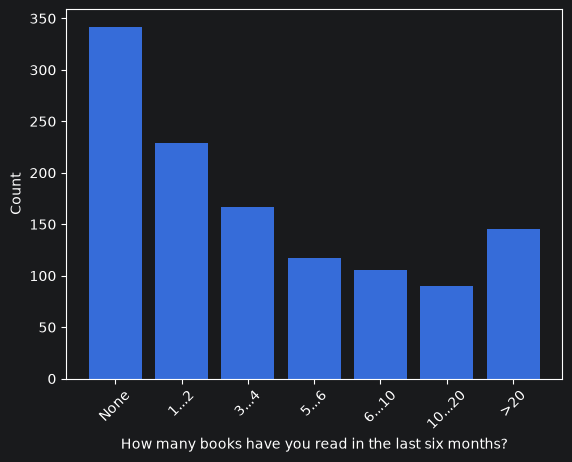

In [10]:
# TODO Assess the factors most responsible for determining a person's reading habits (PCA)
# TODO Determine the feasibility of a model for recommending books to a person according to their answers

def main():
    raw_data: pl.DataFrame = pl.read_csv("Lugeja25.tab", has_header=True, separator="\t")
    typed_data: tp.DataFrame[Answer] = tp.DataFrame(Answer, raw_data)
    # print(typed_data.head(1))
    # predict_habits(typed_data)
    q11_nulls_to_zero_data: tp.DataFrame[AnswerQ11NullsAsOnes] = typed_data.with_columns(typed_data.s.Q11_1.fill_null(strategy="one")).transform(AnswerQ11NullsAsOnes)
    visualize_readership(data=q11_nulls_to_zero_data)


if __name__ == "__main__":
    main()